# Шейплеты PowerCons

Найдем короткие фрагменты суточных профилей потребления, которые помогают различать теплый и холодный сезоны, и сравним два шейплетных классификатора aeon

## Данные

[PowerCons](https://www.timeseriesclassification.com/description.php?Dataset=PowerCons) содержит два класса: 1 — теплый сезон, 2 — холодный сезон, по 180 рядов в TRAIN и TEST и 144 измерения в каждом ряду

Сохраняем официальное разделение, а 36 примеров TRAIN используем для проверки параметров без обращения к TEST

In [ ]:
import os
os.environ.setdefault('NUMBA_NUM_THREADS', '4')
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import RidgeClassifier, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, ExtraTreesClassifier, ExtraTreesRegressor
SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (10, 3.5), 'axes.grid': True, 'grid.alpha': .2})
ROOT = Path.cwd()
DATA = ROOT / 'data' / 'PowerCons'
DATA.mkdir(parents=True, exist_ok=True)
required = [f'PowerCons_{s}.txt' for s in ('TRAIN', 'TEST')]
if not all((DATA / f).exists() for f in required):
    url = 'https://www.timeseriesclassification.com/aeon-toolkit/PowerCons.zip'
    with urlopen(url, timeout=90) as response:
        archive = ZipFile(BytesIO(response.read()))
    for name in required:
        member = next(m for m in archive.namelist() if Path(m).name == name)
        (DATA / name).write_bytes(archive.read(member))
def load_split(name):
    a = np.loadtxt(DATA / f'PowerCons_{name}.txt')
    x, y = a[:, 1:].astype(np.float64), a[:, 0].astype(int)
    assert x.shape == (180, 144) and np.isfinite(x).all()
    assert set(y) == {1, 2}
    return x, y
X_train, y_train = load_split('TRAIN')
X_test, y_test = load_split('TEST')
fit_idx, val_idx = train_test_split(np.arange(180), test_size=.2,
    random_state=SEED, stratify=y_train)
display(pd.DataFrame({'TRAIN': pd.Series(y_train).value_counts(),
                      'TEST': pd.Series(y_test).value_counts()}).rename_axis('Класс'))
print('TRAIN:', X_train.shape, 'TEST:', X_test.shape,
      'fit / validation:', len(fit_idx), len(val_idx))

,TRAIN,TEST
Класс,,
1,90,90
2,90,90


TRAIN: (180, 144) TEST: (180, 144) fit / validation: 144 36


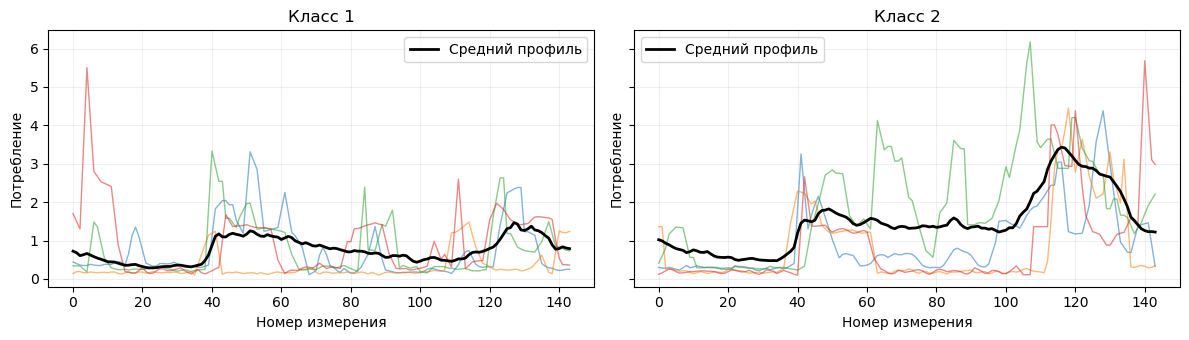

,Среднее,Стандартное отклонение,Минимум,Максимум
count,180.000,180.000,180.00,180.000
mean,1.114,0.909,0.20,4.196
std,0.517,0.302,0.09,1.447
min,0.320,0.260,0.04,1.380
25%,0.739,0.716,0.13,3.245
50%,0.998,0.902,0.22,4.305
75%,1.406,1.098,0.23,5.102
max,2.771,1.576,0.81,7.800


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for cls, ax in zip((1, 2), axes):
    rows = X_train[y_train == cls]
    for row in rows[:4]:
        ax.plot(row, alpha=.55, linewidth=1)
    ax.plot(rows.mean(axis=0), color='black', linewidth=2, label='Средний профиль')
    ax.set(title=f'Класс {cls}', xlabel='Номер измерения', ylabel='Потребление')
    ax.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Среднее': X_train.mean(1), 'Стандартное отклонение': X_train.std(1),
                      'Минимум': X_train.min(1), 'Максимум': X_train.max(1)}).describe().round(3))

Классы сбалансированы, но внутри каждого класса профили заметно различаются, поэтому одного среднего уровня потребления может быть недостаточно

## Поиск фрагментов

Шейплет — короткий фрагмент ряда, расстояние до которого вычисляется по наилучшему совпадению со скользящим окном сигнала

RandomShapeletTransform отбирает фрагменты по приросту информации и превращает расстояния до них в признаки, а RDST дополнительно использует растяжение фрагментов, положение совпадения и число близких окон

Сравним ShapeletTransformClassifier с линейным Ridge и RDSTClassifier, используя исходные 144 точки и нормализацию фрагментов внутри алгоритма

In [ ]:
from aeon.classification.shapelet_based import ShapeletTransformClassifier, RDSTClassifier
from aeon.transformations.collection.shapelet_based import RandomShapeletTransform
import aeon
print('aeon', aeon.__version__)
def make_stc():
    return ShapeletTransformClassifier(n_shapelet_samples=3000, max_shapelets=50,
        estimator=RidgeClassifier(alpha=1), batch_size=100,
        random_state=SEED, n_jobs=4)
def make_rdst():
    return RDSTClassifier(max_shapelets=500, random_state=SEED, n_jobs=4)
factories = {'STC + Ridge': make_stc, 'RDST': make_rdst}
val_rows = []
for name, factory in factories.items():
    m = factory().fit(X_train[fit_idx, None, :], y_train[fit_idx])
    p = m.predict(X_train[val_idx, None, :])
    val_rows.append({'Модель':name, 'Validation Accuracy':accuracy_score(y_train[val_idx], p),
                     'Validation Macro F1':f1_score(y_train[val_idx], p, average='macro')})
display(pd.DataFrame(val_rows).round(4))

aeon 1.3.0


,Модель,Validation Accuracy,Validation Macro F1
0,STC + Ridge,0.8889,0.8885
1,RDST,0.9722,0.9722


## Классификация

После проверки конфигураций на валидации переобучаем оба метода на полном TRAIN и один раз оцениваем на официальном TEST

,Модель,Accuracy,Macro F1,Секунды
1,RDST,0.9889,0.9889,0.0843
0,STC + Ridge,0.9389,0.9389,5.0723


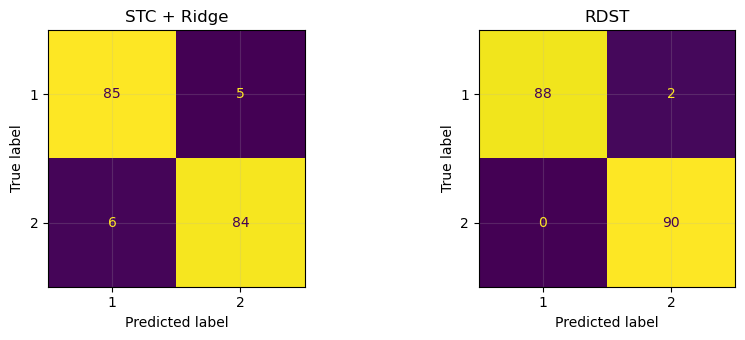

In [ ]:
models, predictions, rows = {}, {}, []
for name, factory in factories.items():
    start = time.perf_counter()
    model = factory().fit(X_train[:, None, :], y_train)
    pred = model.predict(X_test[:, None, :])
    models[name], predictions[name] = model, pred
    rows.append({'Модель':name, 'Accuracy':accuracy_score(y_test, pred),
        'Macro F1':f1_score(y_test, pred, average='macro'),
        'Секунды':time.perf_counter()-start})
results = pd.DataFrame(rows).sort_values('Accuracy', ascending=False)
display(results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Что различает классы

Для интерпретации используем RandomShapeletTransform, уже обученный внутри STC, и выбираем наиболее информативный фрагмент каждого исходного класса только по TRAIN

На графиках выделим лучшее совпадение с рядом каждого класса и покажем расстояния до всех возможных окон, сравнение формы выполняется после стандартизации каждого окна

Отобрано шейплетов: 48
Поля записи: качество, длина, начало, канал, номер ряда, класс, значения


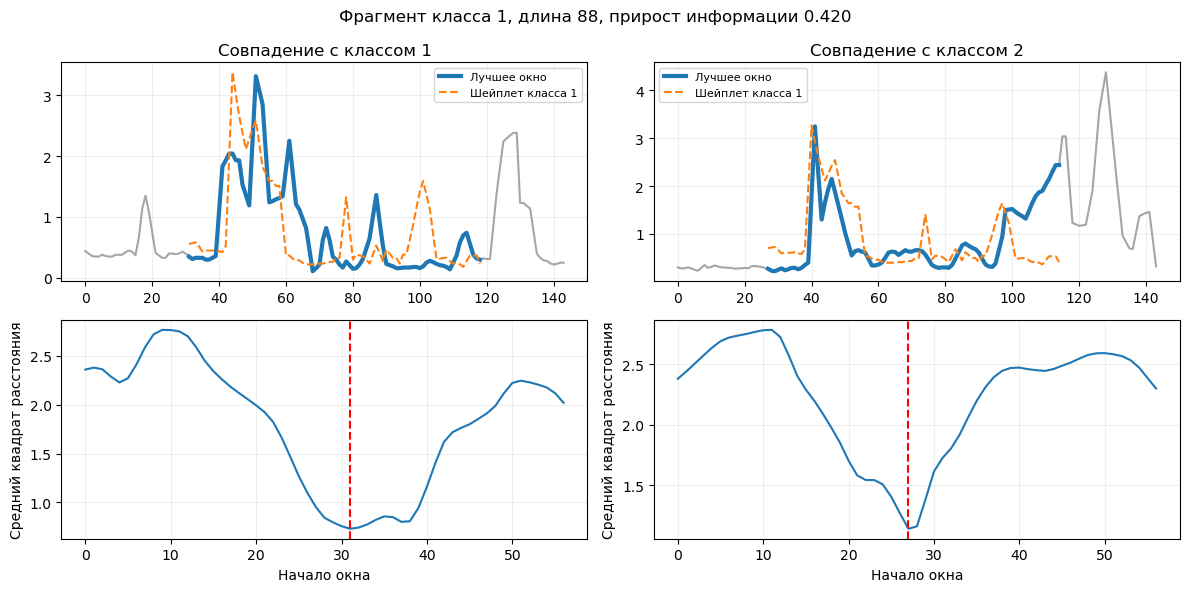

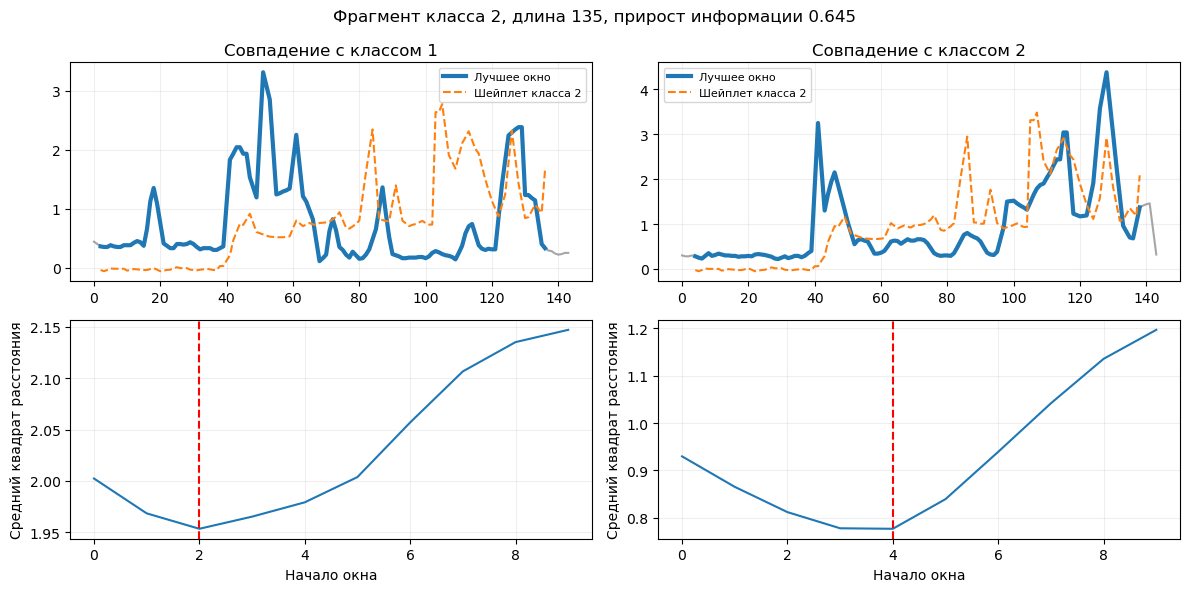

,Класс,Длина,Начало,Ряд TRAIN,Information gain
0,1,88,26,9,0.4196
1,2,135,7,101,0.6452


In [ ]:
transform = models['STC + Ridge']._transformer
assert isinstance(transform, RandomShapeletTransform)
print('Отобрано шейплетов:', len(transform.shapelets))
print('Поля записи: качество, длина, начало, канал, номер ряда, класс, значения')
def znorm(x):
    x = np.asarray(x, dtype=float)
    return (x-x.mean()) / max(x.std(), 1e-12)
shapelet_info = []
for cls in (1, 2):
    candidates = [s for s in transform.shapelets if int(s[5]) == cls]
    assert candidates, f'Нет фрагментов класса {cls}'
    s = max(candidates, key=lambda v:v[0])
    quality, length, start, channel, case, label, values = s[:7]
    shape = znorm(values)
    shapelet_info.append({'Класс': cls, 'Длина': length, 'Начало':start,
                          'Ряд TRAIN':case, 'Information gain':quality})
    fig, axes = plt.subplots(2, 2, figsize=(12, 6))
    for j, target_cls in enumerate((1, 2)):
        sample = X_train[np.flatnonzero(y_train == target_cls)[0]]
        windows = np.lib.stride_tricks.sliding_window_view(sample, int(length))
        norm = (windows-windows.mean(1,keepdims=True))/np.maximum(windows.std(1,keepdims=True),1e-12)
        distances = np.mean((norm-shape)**2, axis=1)
        pos = int(distances.argmin())
        axes[0,j].plot(sample, color='gray', alpha=.7)
        axes[0,j].plot(np.arange(pos,pos+int(length)), sample[pos:pos+int(length)],
                       linewidth=3, label='Лучшее окно')
        overlay = shape*sample[pos:pos+int(length)].std()+sample[pos:pos+int(length)].mean()
        axes[0,j].plot(np.arange(pos,pos+int(length)), overlay, '--', label=f'Шейплет класса {cls}')
        axes[0,j].set_title(f'Совпадение с классом {target_cls}')
        axes[0,j].legend(fontsize=8)
        axes[1,j].plot(distances)
        axes[1,j].axvline(pos, color='red', linestyle='--')
        axes[1,j].set(xlabel='Начало окна', ylabel='Средний квадрат расстояния')
    fig.suptitle(f'Фрагмент класса {cls}, длина {length}, прирост информации {quality:.3f}')
    plt.tight_layout()
    plt.show()
display(pd.DataFrame(shapelet_info).round(4))

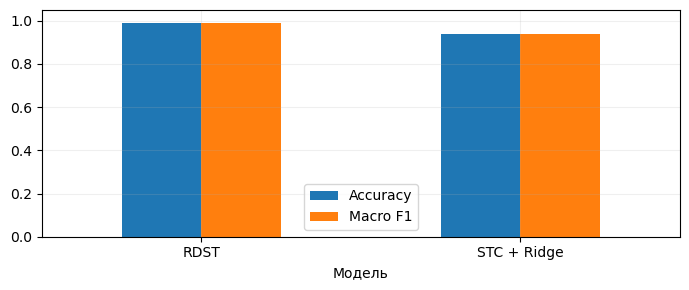

## Выводы

Лучший результат на TEST у RDST: Accuracy 0.989, Macro F1 0.989

Шейплеты выделяют локальные подъемы и спады потребления, а поиск по окнам позволяет находить похожую форму при сдвиге во времени

Найденные фрагменты различают сезоны статистически, но сами по себе не доказывают физическую причину различий, оценка ограничена 180 тестовыми рядами

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3))
results.set_index('Модель')[['Accuracy','Macro F1']].plot.bar(ax=ax, rot=0, ylim=(0,1.05))
plt.tight_layout()
plt.show()
out = ROOT / 'outputs' / 'lab09'
out.mkdir(parents=True, exist_ok=True)
results.to_csv(out / 'metrics.csv', index=False)
best = results.iloc[0]
display(Markdown(f"## Выводы\n\nЛучший результат на TEST у {best['Модель']}: "
    f"Accuracy {best['Accuracy']:.3f}, Macro F1 {best['Macro F1']:.3f}\n\n"
    "Шейплеты выделяют локальные подъемы и спады потребления, а поиск по окнам позволяет находить похожую форму при сдвиге во времени\n\n"
    "Найденные фрагменты различают сезоны статистически, но сами по себе не доказывают физическую причину различий, оценка ограничена 180 тестовыми рядами"))